In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel(r"C:\Users\dell\Downloads\bakery_synthetic_dataset.csv (1).xlsx").dropna(axis=1)
df.head()

,Transaction_ID,Date,Time,Customer_ID,Customer_Age,Customer_Gender,Product,Category,Quantity,Unit_Price,...,Expiry_Risk,Promotion_Applied,Promotion_Score,Customer_Rating,Customer_Segment,Loyalty_Member,Profit,Waste_Cost,Recommended_Product,Recommended_Discount
0,TXN000038,2023-01-01,07:13:00,CUST01289,32,Male,Rusk,Biscuits & Cookies,1,34.79,...,Medium,Yes,100,4,Young Professional,Yes,-4.28,7.71,Rusk,13.0
1,TXN000039,2023-01-01,07:13:00,CUST01289,32,Male,Peanut Butter,Spreads,4,176.62,...,Low,Yes,100,4,Young Professional,Yes,-105.15,171.43,Bread,9.0
2,TXN000040,2023-01-01,07:13:00,CUST01289,32,Male,Black Forest Cake,Cakes,2,448.03,...,Medium,Yes,100,4,Young Professional,Yes,-461.14,520.00,Soft Drink,14.7
3,TXN000041,2023-01-01,07:13:00,CUST01289,32,Male,Honey,Spreads,4,219.12,...,Low,Yes,100,4,Young Professional,Yes,-92.52,222.86,Honey,3.3
4,TXN000043,2023-01-01,08:15:00,CUST01077,17,Female,Tea,Beverages,2,29.85,...,High,Yes,100,4,Student,No,-0.66,24.00,Biscuit,25.2


In [2]:
df.isnull().sum()

Transaction_ID          0
Date                    0
Time                    0
Customer_ID             0
Customer_Age            0
Customer_Gender         0
Product                 0
Category                0
Quantity                0
Unit_Price              0
Discount_Percentage     0
Discount_Amount         0
Selling_Price           0
Total_Bill              0
Payment_Method          0
Weather                 0
Temperature             0
Season                  0
Day_of_Week             0
Weekend                 0
Store_ID                0
Employee_ID             0
Shelf_Life_Days         0
Manufacturing_Date      0
Expiry_Date             0
Stock_Available         0
Units_Produced          0
Units_Sold              0
Unsold_Units            0
Expiry_Risk             0
Promotion_Applied       0
Promotion_Score         0
Customer_Rating         0
Customer_Segment        0
Loyalty_Member          0
Profit                  0
Waste_Cost              0
Recommended_Product     0
Recommended_

In [3]:
df.shape

(16569, 39)

In [4]:
transaction = df.groupby(['Date','Time','Customer_ID'])['Category'].apply(lambda x:list(set(x)))
transaction

Date        Time      Customer_ID
2023-01-01  07:13:00  CUST01289                   [Spreads, Cakes, Biscuits & Cookies]
            08:15:00  CUST01077                                   [Spreads, Beverages]
            08:29:00  CUST01555                                   [Biscuits & Cookies]
            08:43:00  CUST01329                       [Spreads, Cakes, Bakery Staples]
            08:55:00  CUST00414                                       [Spreads, Dairy]
                                                           ...                        
2024-12-31  16:03:00  CUST00632      [Spreads, Beverages, Bakery Staples, Savoury S...
            16:13:00  CUST01577                                            [Beverages]
            17:43:00  CUST01436                                             [Cupcakes]
            18:10:00  CUST00836                             [Bakery Snacks, Beverages]
            20:05:00  CUST01217                                       [Bakery Staples]
Name: Cat

In [5]:
transactions = df.groupby(['Date','Time','Customer_ID'])['Category'].apply(lambda x:list(set(x))).tolist()
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [6]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)
df_encoded.head()

,Bakery Snacks,Bakery Staples,Beverages,Biscuits & Cookies,Cakes,Cupcakes,Dairy,Muffins,Savoury Snacks,Spreads
0,False,False,False,True,True,False,False,False,False,True
1,False,False,True,False,False,False,False,False,False,True
2,False,False,False,True,False,False,False,False,False,False
3,False,True,False,False,True,False,False,False,False,True
4,False,False,False,False,False,False,True,False,False,True


In [7]:
frequent_itemsets = apriori(df_encoded,min_support=0.01,use_colnames=True)
frequent_itemsets.head()

,support,itemsets
0,0.098033,frozenset({Bakery Snacks})
1,0.202514,frozenset({Bakery Staples})
2,0.304044,frozenset({Beverages})
3,0.148634,frozenset({Biscuits & Cookies})
4,0.192896,frozenset({Cakes})


In [8]:
rule = association_rules(frequent_itemsets,metric='lift',min_threshold=1.0)
rule[['antecedents','consequents','support','confidence','lift']]

,antecedents,consequents,support,confidence,lift
0,frozenset({Bakery Snacks}),frozenset({Beverages}),0.033333,0.340022,1.118334
1,frozenset({Beverages}),frozenset({Bakery Snacks}),0.033333,0.109633,1.118334
2,frozenset({Dairy}),frozenset({Bakery Staples}),0.062951,0.250435,1.236632
3,frozenset({Bakery Staples}),frozenset({Dairy}),0.062951,0.310847,1.236632
4,frozenset({Spreads}),frozenset({Bakery Staples}),0.045137,0.338802,1.672985
5,frozenset({Bakery Staples}),frozenset({Spreads}),0.045137,0.222882,1.672985
6,frozenset({Cakes}),frozenset({Beverages}),0.058798,0.304816,1.002540
7,frozenset({Beverages}),frozenset({Cakes}),0.058798,0.193386,1.002540
8,frozenset({Beverages}),frozenset({Muffins}),0.027541,0.090582,1.126125
9,frozenset({Muffins}),frozenset({Beverages}),0.027541,0.342391,1.126125


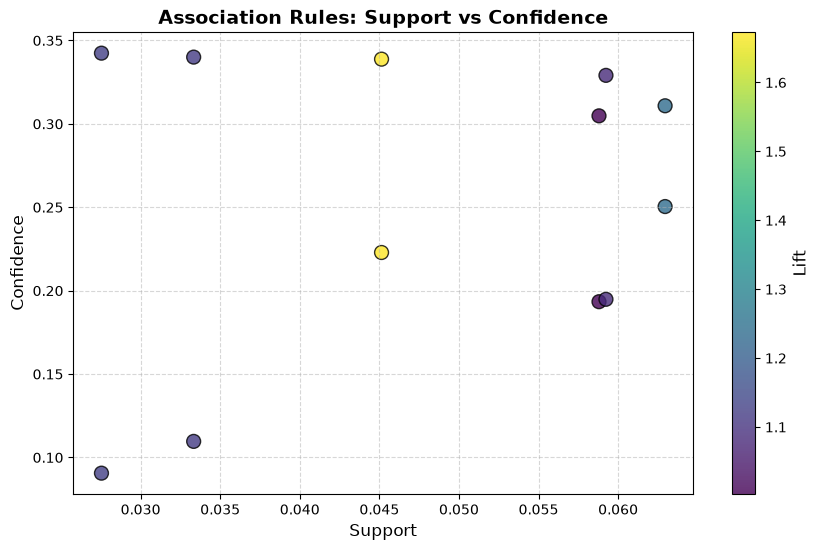

In [9]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rule['support'], 
    rule['confidence'], 
    c=rule['lift'], 
    cmap='viridis', 
    s=100, 
    alpha=0.8,
    edgecolors='black'
)

cbar = plt.colorbar(scatter)
cbar.set_label('Lift', fontsize=12)

plt.title('Association Rules: Support vs Confidence', fontsize=14, fontweight='bold')
plt.xlabel('Support', fontsize=12)
plt.ylabel('Confidence', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

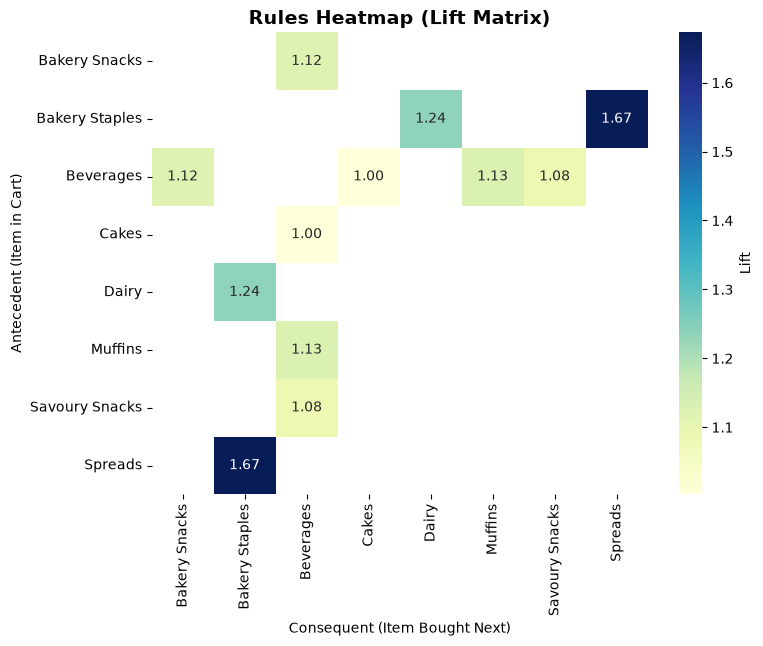

In [10]:
import seaborn as sns

# frozenset ko string me convert karein
rule['antecedent_str'] = rule['antecedents'].apply(lambda x: ', '.join(list(x)))
rule['consequent_str'] = rule['consequents'].apply(lambda x: ', '.join(list(x)))

# Pivot table banayein
pivot_lift = rule.pivot(index='antecedent_str', columns='consequent_str', values='lift')

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_lift, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Lift'})
plt.title('Rules Heatmap (Lift Matrix)', fontsize=14, fontweight='bold')
plt.xlabel('Consequent (Item Bought Next)')
plt.ylabel('Antecedent (Item in Cart)')
plt.show()

In [12]:
df.shape

(16569, 39)

In [13]:
import numpy as np

# Data ko 3 barabar hisso me split karna
splits = np.array_split(df, 3)

part1 = splits[0]
part2 = splits[1]
part3 = splits[2]

In [15]:
df1 = pd.DataFrame(part1,columns=df.columns)
df1.head()

,Transaction_ID,Date,Time,Customer_ID,Customer_Age,Customer_Gender,Product,Category,Quantity,Unit_Price,...,Expiry_Risk,Promotion_Applied,Promotion_Score,Customer_Rating,Customer_Segment,Loyalty_Member,Profit,Waste_Cost,Recommended_Product,Recommended_Discount
0,TXN000038,2023-01-01,07:13:00,CUST01289,32,Male,Rusk,Biscuits & Cookies,1,34.79,...,Medium,Yes,100,4,Young Professional,Yes,-4.28,7.71,Rusk,13.0
1,TXN000039,2023-01-01,07:13:00,CUST01289,32,Male,Peanut Butter,Spreads,4,176.62,...,Low,Yes,100,4,Young Professional,Yes,-105.15,171.43,Bread,9.0
2,TXN000040,2023-01-01,07:13:00,CUST01289,32,Male,Black Forest Cake,Cakes,2,448.03,...,Medium,Yes,100,4,Young Professional,Yes,-461.14,520.0,Soft Drink,14.7
3,TXN000041,2023-01-01,07:13:00,CUST01289,32,Male,Honey,Spreads,4,219.12,...,Low,Yes,100,4,Young Professional,Yes,-92.52,222.86,Honey,3.3
4,TXN000043,2023-01-01,08:15:00,CUST01077,17,Female,Tea,Beverages,2,29.85,...,High,Yes,100,4,Student,No,-0.66,24.0,Biscuit,25.2


In [16]:
df1.shape

(5523, 39)

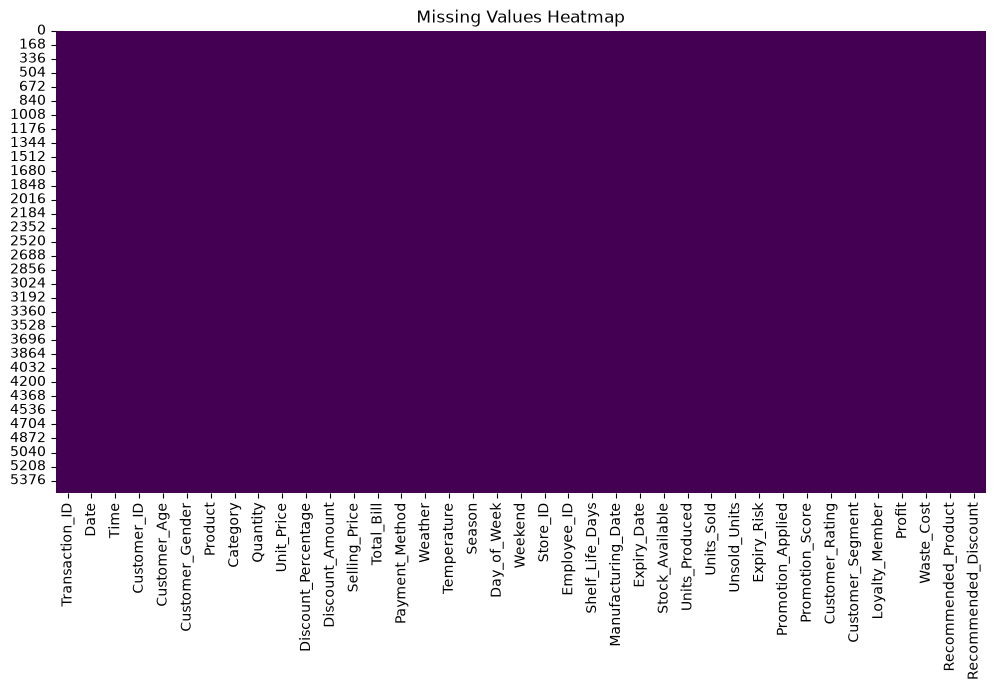

In [25]:
plt.figure(figsize=(12, 6))
sns.heatmap(df1.isnull(),cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()